# Explainable AI: understanding resale-price predictions

## Introduction

A price model can predict well while remaining difficult to understand. This notebook revisits *Explainable Artificial Intelligence* through three questions: which features does a fitted model rely on, how do its predictions vary with a feature, and why did it forecast this particular laptop's price?

The worked examples fit a tree ensemble, build a simple surrogate, explore permutation importance and PDP/ICE plots, and reconstruct an individual prediction from SHAP values. The application returns to the local laptop-resale data so you can focus on the explanations.

**Outline:** [Key Concepts](#key-concepts) · [XAI foundations](#xai-foundations) · [Global explanation methods](#global-explanation-methods) · [Local and example-based explanations](#local-and-example-based-explanations) · [Summary](#summary) · [Tasks](#tasks)

**Lecture connection:** slides 7–9 (stakeholders and interpretable models), 11–22 (surrogates, permutation importance and PDP), and 25–44 (local, SHAP and example-based explanations). Page references count PDF pages; some late-slide printed numbers differ.

We'll use **pandas** to organize the resale data, **NumPy** to reconstruct predictions, and **Matplotlib** to visualize the explanations. **Scikit-learn** supplies the model and global explanation tools, while **SHAP** provides the local contributions. The saved notebook includes the resulting plots.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_absolute_error
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

# Reuse one seed for every random operation in this notebook.
SEED = 67

# SHAP beeswarm jitter uses NumPy’s global random-number generator.
np.random.seed(SEED)


/Users/stefanlessmann/Seafile/Meine Bibliothek/lecture/ESMT_Intro_ML/coding/git/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Key Concepts

Let $\widehat{f}(\mathbf{x}_i)$ be a fitted resale-price forecast for observation $i$ with $d$ features. **Global** explanations summarize behavior across many observations; **local** explanations focus on a particular prediction.

*Permutation importance* measures the decrease in a chosen performance score when a feature is shuffled, holding the fitted model fixed. The calculation evaluates the original fitted model on shuffled inputs.

For a feature $j$ and a candidate value $v$, define $\mathbf{x}_i^{(j\leftarrow v)}$ as row $i$ with feature $j$ replaced by $v$. A *partial dependence* average over $n$ reference rows is

$$\operatorname{PD}_j(v)=\frac{1}{n}\sum_{i=1}^{n}\widehat{f}(\mathbf{x}_i^{(j\leftarrow v)}).$$

An *ICE* curve keeps the individual predictions before averaging. It can reveal different model responses for different rows that a single average conceals.

For a local SHAP explanation, let $\phi_{i0}$ be the baseline output and $\phi_{ij}$ the contribution of feature $j$. The additive accounting is

$$\widehat{f}(\mathbf{x}_i)=\phi_{i0}+\sum_{j=1}^{d}\phi_{ij}.$$

Here all terms are in **USD**. Contributions depend on the model, the explained row and the background/missing-feature convention. They explain a model output relative to a reference; causal effects and prediction errors require their own analyses.

## XAI foundations

### Define the prediction time and the explanation audience

We forecast a laptop's resale price **at return, before sale**, using its original retail price (USD), actual lease duration (months) and measured battery capacity (%). These inputs are available at equipment return.

A remarketing analyst might want a global view of price drivers. A colleague reviewing one forecast might want a local explanation. Both need understandable units and a clear account of what the model actually predicts.

Explanations are part of model inspection and facilitate subsequent analysis of, e.g., model fairness, safety, etx.

The code converts numerical features to floating-point values with `.astype(float)`. Partial-dependence calculations replace them with grid values that can fall between the observed integers, including fractional months.

In [3]:
resale = pd.read_csv('../data/resale_price_dataset.csv')
features = ['Retail price', 'Actual Lease Duration (months)', 'Battery capacity (%)']
X = resale[features].astype(float)
y = resale['Observed resale price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
model = GradientBoostingRegressor(
    n_estimators=100, max_depth=2, learning_rate=0.05, random_state=SEED
)
model.fit(X_train, y_train)
print(f'Test MAE: {mean_absolute_error(y_test, model.predict(X_test)):.2f} USD')
X_test.head()

Test MAE: 122.82 USD


,Retail price,Actual Lease Duration (months),Battery capacity (%)
3715,1009.0,35.0,93.31
643,3569.0,38.0,97.91
4375,3439.0,28.0,96.22
3676,729.0,13.0,89.46
4636,1289.0,42.0,90.26


The fitted model stays fixed throughout the explanations. The first 200 held-out rows form a manageable reference set for plots and SHAP calculations. Selection follows the existing row order. Global findings below describe this subset of laptops.

Retaining the row indices keeps observations, predictions and explanations aligned.

In [4]:
X_explain = X_test.iloc[:200].copy()
y_explain = y_test.loc[X_explain.index]
print(f'Explanation reference rows: {len(X_explain)}')
X_explain.corr().round(2)

Explanation reference rows: 200


,Retail price,Actual Lease Duration (months),Battery capacity (%)
Retail price,1.00,-0.03,-0.01
Actual Lease Duration (months),-0.03,1.00,-0.05
Battery capacity (%),-0.01,-0.05,1.00


The correlation table provides context for the synthetic feature combinations used below. Strong feature dependence makes independent replacements especially prone to creating unrealistic combinations.

## Global explanation methods

### A simple surrogate for ensemble predictions

The next cell fits a small regression tree to **ensemble predictions** on the training features. This tree is a *surrogate*: it summarizes an opaque predictor using a short set of rules. Its training targets are the ensemble forecasts.

Its fidelity is measured on held-out rows by comparing surrogate predictions with ensemble predictions. Fidelity measures agreement with ensemble predictions. Predictive MAE measures agreement with actual prices.

Surrogate fidelity MAE: 163.01 USD


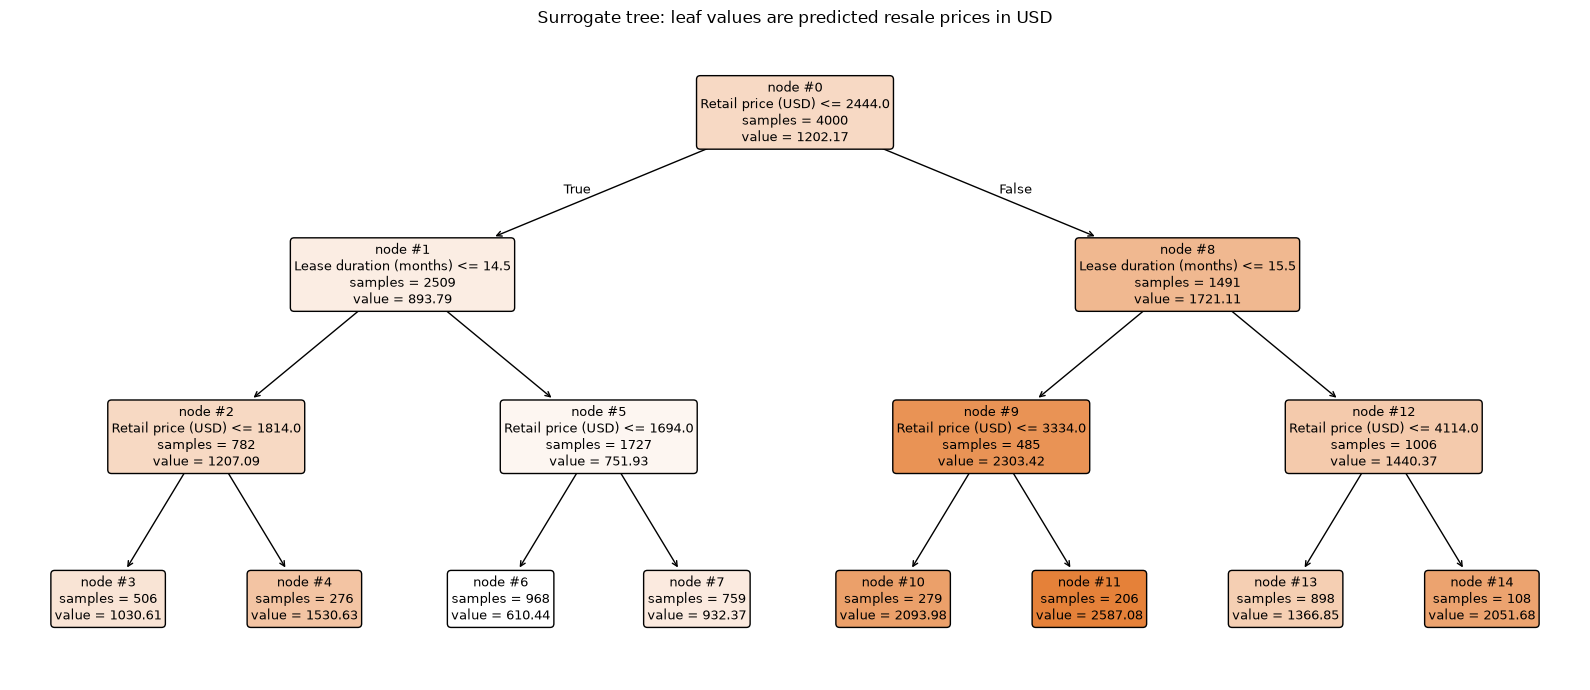

In [7]:
surrogate = DecisionTreeRegressor(max_depth=3, min_samples_leaf=50, random_state=SEED)
surrogate.fit(X_train, model.predict(X_train))
fidelity_mae = mean_absolute_error(model.predict(X_explain), surrogate.predict(X_explain))
print(f'Surrogate fidelity MAE: {fidelity_mae:.2f} USD')
# Each node shows its split, number of training cases and mean ensemble forecast.
# Short display names include units; the fitted feature columns remain unchanged.
fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(
    surrogate, feature_names=['Retail price (USD)', 'Lease duration (months)', 'Battery capacity (%)'],
    filled=True, rounded=True, impurity=False, node_ids=True, precision=2,
    fontsize=9, ax=ax
)
ax.set_title('Surrogate tree: leaf values are predicted resale prices in USD')
plt.tight_layout()
plt.show()

The tree gives a visual explanation of the surrogate’s forecast. Starting at the root, a true `<=` condition leads left and a false condition leads right. Each leaf’s `value` is the mean **ensemble forecast** among the training laptops reaching that leaf. `samples` shows how many training laptops contributed to the node.

### Follow one laptop through the tree

Consider a laptop with a retail price of 2,200 USD, a lease duration of 36 months and a measured battery capacity of 90%. The next cell creates this hypothetical return profile and calculates both forecasts. `apply` identifies the surrogate leaf, making it possible to check the leaf’s training mean directly.

In [8]:
example_laptop = pd.DataFrame({
    'Retail price': [2200.0],
    'Actual Lease Duration (months)': [36.0],
    'Battery capacity (%)': [90.0]
})

# Compare the readable surrogate with the ensemble it approximates.
example_forecast = surrogate.predict(example_laptop)[0]
ensemble_forecast = model.predict(example_laptop)[0]
example_leaf = surrogate.apply(example_laptop)[0]

# The surrogate was trained on ensemble predictions, so its leaf value is
# their average among training laptops routed to the same leaf.
leaf_members = surrogate.apply(X_train) == example_leaf
leaf_mean = model.predict(X_train.loc[leaf_members]).mean()
print(f'Surrogate leaf: {example_leaf}')
print(f'Training laptops in this leaf: {leaf_members.sum()}')
print(f'Mean ensemble forecast in the leaf: {leaf_mean:.2f} USD')
print(f'Surrogate forecast: {example_forecast:.2f} USD')
print(f'Ensemble forecast for this laptop: {ensemble_forecast:.2f} USD')

Surrogate leaf: 7
Training laptops in this leaf: 759
Mean ensemble forecast in the leaf: 932.37 USD
Surrogate forecast: 932.37 USD
Ensemble forecast for this laptop: 998.24 USD


<p style="color: red;"><strong>Disclaimer: Please note that the following interpretation assumes you executed the original code. Changes can invalidate our interpretation.</strong></p>

For this laptop, the path through the plotted tree is:

1. **Retail price ≤ 2,444 USD:** 2,200 satisfies the condition, so the path goes left.
2. **Lease duration ≤ 14.5 months:** 36 exceeds the threshold, so the path goes right.
3. **Retail price ≤ 1,694 USD:** 2,200 exceeds the threshold, so the path goes right to **leaf 7**.

Leaf 7 forecasts **932.37 USD**. Every laptop reaching this leaf receives that forecast. Battery capacity appears in the input profile, while the fitted surrogate’s splits use retail price and duration.

The explanation is therefore: “The laptop falls in the group priced between 1,694 and 2,444 USD, with a lease duration above 14.5 months. The ensemble’s average training forecast for that group is 932.37 USD.”

The ensemble forecasts **998.24 USD** for this particular profile, about **65.87 USD** above the surrogate. This local difference shows the approximation involved in summarizing the ensemble with a small tree. The SHAP section later explains the ensemble’s individual forecast through feature contributions.

The short rules approximate the ensemble. Fidelity error quantifies the discrepancy between their predictions.

### Permutation importance

![XAI lecture slide 12: corrupting one feature tests how strongly a fixed model relies on its information.](../resources/6_permutation_importance.png)

`permutation_importance` shuffles one column at a time and reevaluates the model. The example specifies `scoring='neg_mean_absolute_error'`: **scikit-learn** expects larger scores to be better, so it negates MAE. The reported score decrease therefore equals the **increase in MAE**, in USD, after shuffling.

Five repetitions of each shuffle show sensitivity to the random permutations. A negative result means the shuffled predictions happened to improve this subset's MAE.

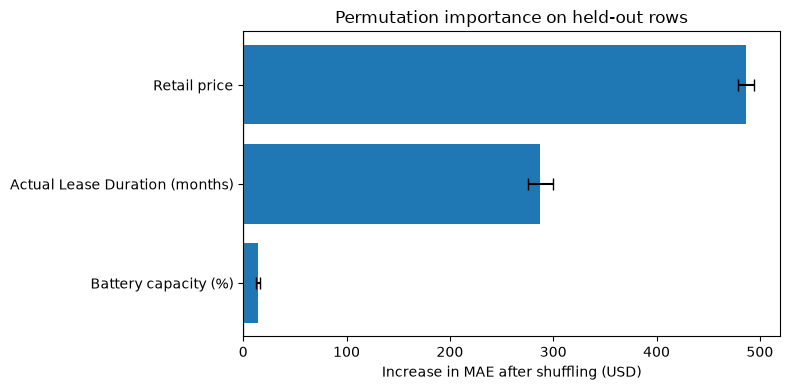

,feature,mean_mae_increase_usd,shuffle_std_usd
2,Battery capacity (%),14.47,2.16
1,Actual Lease Duration (months),287.66,12.11
0,Retail price,487.02,7.75


In [6]:
importance = permutation_importance(
    model, X_explain, y_explain, scoring='neg_mean_absolute_error',
    n_repeats=5, random_state=SEED
)
importance_table = pd.DataFrame({
    'feature': features,
    'mean_mae_increase_usd': importance.importances_mean,
    'shuffle_std_usd': importance.importances_std
}).sort_values('mean_mae_increase_usd')
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(importance_table['feature'], importance_table['mean_mae_increase_usd'],
        xerr=importance_table['shuffle_std_usd'], capsize=4)
ax.axvline(0, color='gray', linewidth=1)
ax.set(xlabel='Increase in MAE after shuffling (USD)', title='Permutation importance on held-out rows')
plt.tight_layout()
plt.show()
importance_table.round(2)

Longer bars indicate stronger reliance under this metric and reference sample. The error bars summarize variation across repeated shuffles of these rows. Correlated features may share or substitute for predictive information, so rankings depend on the fitted model and evaluation data.

### Partial dependence and individual curves

The next cell calculates three average forecasts after replacing lease duration with 12, 36 and 60 months, making the PDP calculation explicit. All other columns stay at their reference values. The forecasts refer to hypothetical modified rows.

In [7]:
duration_feature = 'Actual Lease Duration (months)'
pdp_rows = []
for duration in [12, 36, 60]:
    modified = X_explain.copy()
    modified[duration_feature] = duration
    pdp_rows.append({'duration_months': duration, 'average_forecast_usd': model.predict(modified).mean()})
pd.DataFrame(pdp_rows).round(2)

,duration_months,average_forecast_usd
0,12,1538.94
1,36,970.56
2,60,903.04


`PartialDependenceDisplay` extends this calculation over a grid. `kind='both'` draws the average PDP and individual ICE curves; `subsample=40` limits the displayed individual curves. The PDP still averages over the supplied reference set. `method='brute'` computes predictions on modified rows directly, matching the calculation above.

The returned display stores the actual plotting axes in `axes_`. The code sets the labels on its first axis so that the feature and price units appear on the plot.

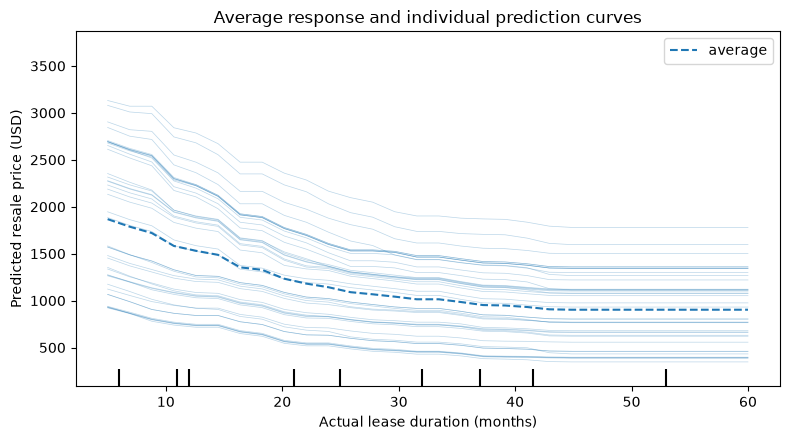

In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
pdp_display = PartialDependenceDisplay.from_estimator(
    model, X_explain, features=[duration_feature], kind='both',
    subsample=40, random_state=SEED, method='brute', grid_resolution=30, ax=ax
)
pdp_display.axes_[0, 0].set(xlabel='Actual lease duration (months)', ylabel='Predicted resale price (USD)',
       title='Average response and individual prediction curves')
plt.tight_layout()
plt.show()

Read the average direction and compare the individual curves. Parallel curves suggest similar responses over the plotted range; differences in their shapes suggest interactions in the fitted model. The small marks on the horizontal axis indicate feature deciles.

![XAI lecture slide 22: dependence between features and heterogeneous responses limit what an average PDP can show.](../resources/6_pdp_limits.png)

This describes a response of the **fitted prediction function**. Replacing one feature can create combinations absent from training, and an average can hide individual variation. A causal conclusion needs assumptions and evidence beyond this plot.

## Local and example-based explanations

### SHAP: allocate the difference from a baseline

![XAI lecture slide 27: feature contributions move a baseline prediction toward an individual forecast.](../resources/6_shap_example.png)

<p style="color: red;"><strong>Disclaimer: Please note that the following interpretation assumes you executed the original code. Changes can invalidate our interpretation.</strong></p>

The slide illustrates a credit-class probability; our example explains a **resale-price forecast in USD**. Positive contributions push the price above the reference level, and negative contributions push it below.

`TreeExplainer` exploits the tree structure. Our example supplies 100 sampled training rows as the background and explicitly sets `feature_perturbation='interventional'`. Missing-feature contributions are defined using replacements from this background. The term *interventional* names this computational replacement convention.

For this regression model, `model_output='raw'` is the price prediction itself. With a binary classifier, output units can be probabilities or log-odds depending on the model and explainer settings, so the output scale depends on that configuration.

In [9]:
background = X_train.sample(n=100, random_state=SEED)
explainer = shap.TreeExplainer(
    model, data=background, feature_perturbation='interventional', model_output='raw'
)
shap_values = explainer(X_explain)
print('SHAP array shape (rows, features):', shap_values.values.shape)
print(f'Baseline forecast: {shap_values.base_values[0]:.2f} USD')
print(f'Mean model forecast on background: {model.predict(background).mean():.2f} USD')

SHAP array shape (rows, features): (200, 3)
Baseline forecast: 1174.63 USD
Mean model forecast on background: 1174.63 USD


The `Explanation` object keeps feature values, contribution values and baselines together. In this regression problem, `.values` has one column per feature.

The next cell checks the additive accounting before the contributions are plotted. Summing across `axis=1` adds feature contributions for each explained row.

In [10]:
reconstructed = shap_values.base_values + shap_values.values.sum(axis=1)
model_forecast = model.predict(X_explain)
print(f'Largest reconstruction difference: {np.abs(reconstructed - model_forecast).max():.6f} USD')
local_row = 0
local_table = pd.DataFrame({
    'feature_value': X_explain.iloc[local_row],
    'contribution_usd': shap_values.values[local_row]
})
print(f'Explained row index: {X_explain.index[local_row]}')
print(f'Forecast: {model_forecast[local_row]:.2f} USD; actual price: {y_explain.iloc[local_row]:.2f} USD')
local_table.round(2)

Largest reconstruction difference: 0.000011 USD
Explained row index: 3715
Forecast: 474.62 USD; actual price: 437.00 USD


,feature_value,contribution_usd
Retail price,1009.00,-536.57
Actual Lease Duration (months),35.00,-182.26
Battery capacity (%),93.31,18.82


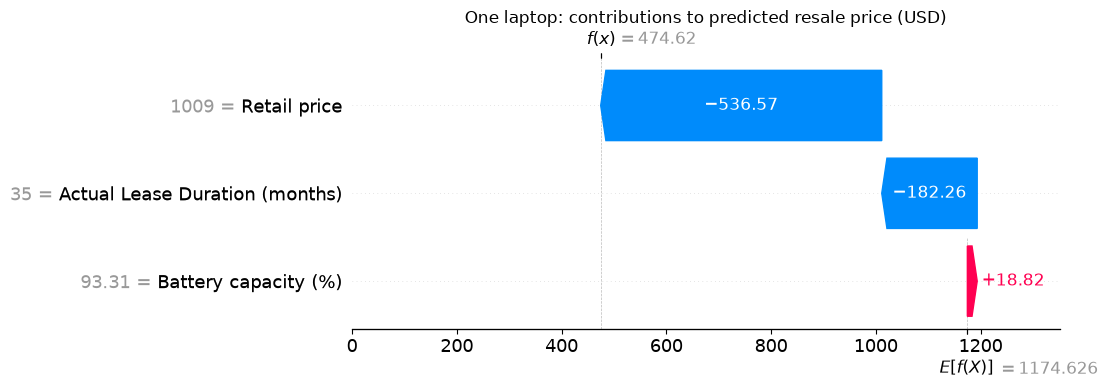

In [11]:
shap.plots.waterfall(shap_values[local_row], max_display=3, show=False)
plt.gcf().set_size_inches(11, 4)
# Keep the USD scale consistent on the main and annotation axes.
for axis in plt.gcf().axes:
    axis.set_xlim(0, max(shap_values.base_values[local_row], model_forecast[local_row]) * 1.15)
plt.title('One laptop: contributions to predicted resale price (USD)')
plt.tight_layout()
plt.show()

The waterfall plot starts at the baseline and adds the feature contributions to arrive at the forecast. The baseline is the average **model forecast** over the chosen background. The actual sale price is a separate observed quantity.

### Aggregate local contributions

A beeswarm plot places one contribution per feature and explained row. Horizontal position is the SHAP contribution in USD; color indicates that feature's value. The ranking uses mean absolute SHAP magnitude. It answers a different question from permutation importance, which measures lost predictive performance after corruption.

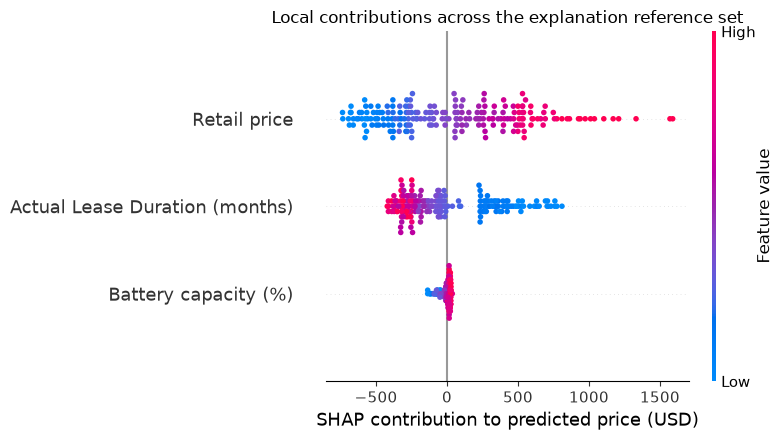

In [12]:
shap.plots.beeswarm(shap_values, max_display=3, show=False, plot_size=(8, 4.5))
plt.xlabel('SHAP contribution to predicted price (USD)')
plt.title('Local contributions across the explanation reference set')
plt.tight_layout()
plt.show()

Inspect whether high feature values tend to have positive or negative contributions. The two rankings summarize different quantities: one summarizes output differences relative to a background, while the other summarizes changes in error after shuffling.

### Explain through modified examples

The final example constructs two hypothetical return profiles at different lease durations, holding retail price and battery capacity constant. This illustrates a *what-if* comparison. The two profiles specify different equipment-return scenarios.

A strict *counterfactual explanation* would specify a desired model output, a distance measure and feasibility constraints, then search for a change satisfying them. The lecture also distinguishes adversarial modifications whose purpose is to induce errors.

In [13]:
profiles = pd.DataFrame({
    'Retail price': [2200, 2200],
    'Actual Lease Duration (months)': [24, 36],
    'Battery capacity (%)': [90, 90]
}, index=['Return after 24 months', 'Return after 36 months'])
profiles['predicted_price_usd'] = model.predict(profiles[features])
profiles.round(2)

,Retail price,Actual Lease Duration (months),Battery capacity (%),predicted_price_usd
Return after 24 months,2200,24,90,1176.46
Return after 36 months,2200,36,90,998.24


These forecasts describe model responses to the specified inputs. Estimating actual sale-price changes under an intervention would require causal assumptions and evidence.

## Summary

- Different audiences and questions call for different explanations: global reliance, average response or one local prediction.
- A surrogate's fidelity measures agreement with the fitted model.
- Permutation importance measures a fixed model’s reliance on features under a chosen metric and reference sample.
- PDP averages modified-row predictions; ICE reveals individual responses. Causal interpretation requires additional assumptions and evidence.
- SHAP contributions add to the prediction relative to a specified background and output scale.
- Fairness, business value and feasibility require assessments matched to their own objectives.

Here's a quick reference for the new Python tools introduced in this notebook:

| Python pattern | What it helps you do |
|---|---|
| `.corr()` | Inspect dependence between explanation features |
| `permutation_importance` | Measure the increase in price error after shuffling a feature |
| `PartialDependenceDisplay.from_estimator(..., kind='both')` | Display average and individual model responses |
| `.sample(n=100, random_state=SEED)` | Select a reproducible explanation background |
| `shap.TreeExplainer` | Calculate additive tree-model explanations |
| `Explanation.base_values`, `Explanation.values` | Retrieve the baseline and feature contributions for reconstruction |
| `shap.plots.waterfall`, `shap.plots.beeswarm` | Inspect one explanation and aggregate local explanations |
| `ax.barh(..., xerr=...)` | Plot importance and shuffle variation in explicit units |

## Tasks

### Task 1: Explain another laptop

Choose a different positional row from `X_explain`. Report its baseline, each contribution and the reconstructed forecast, then make a waterfall plot. Explain the largest contribution as a change from the model’s baseline forecast.

In [14]:
# YOUR CODE: explain and reconstruct another forecast.

### Task 2: Make the PDP calculation explicit

For battery capacities 70, 85 and 95 percent, replace the battery column in a copy of `X_explain` and calculate the average forecast. Compare those values with a battery PDP. Discuss whether all modified profiles are well supported by the original data.

In [15]:
# YOUR CODE: manually calculate three battery partial-dependence values.

### Task 3: Check the surrogate locally

Compare the surrogate and ensemble forecast for three rows in `X_explain`. Show their absolute differences and explain how individual discrepancies can vary around the average fidelity error.

*Hint:* use `surrogate.predict` and `model.predict` on the same rows.

In [16]:
# YOUR CODE: inspect individual surrogate discrepancies.